# YOLO + ByteTrack + Pose -> 30 s SEI (Camera-03 / Camera-04)

Notebook-first, self-contained pipeline for the two fixed **30 s** clips:

`YOLO detect + ByteTrack IDs -> face geometry -> conditional pose -> pose yaw within ±60° -> dwell/exposure runs -> 30 s SEI table`

- **Camera-03** has two physical pillar faces (blue/left + orange/right). They are treated as **one combined screen**: one foot-traffic count, one median dwell, and exposure runs merged across both faces.
- **Camera-04** is a single beverage screen facing the left aisle.
- Foot traffic is **dwell-gated**: unique ByteTrack IDs with at least one in-zone frame.
- Qualified views require **pose yaw** within ±60° of the screen bearing. Posture-only facing is shown as a diagnostic, not counted in the SEI.
- The SEI table is **raw over the shared 30 s window**. There is no hourly extrapolation.

**Run:** `uv sync && uv run --with jupyter jupyter lab pipeline/run_pipeline.ipynb` -> Run All.
Config: `pipeline/configs/pipeline.yaml`. Calibrations: `pipeline/calibration/cam03.json`, `cam04.json`. Weights: `pipeline/weights/`.


In [1]:
import json
import math
import subprocess
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path
from statistics import median

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Markdown, display
from pydantic import BaseModel, Field
from scipy.optimize import linear_sum_assignment


def resolve_repo_root(start: Path) -> Path:
    """Walk up until we find the repo root (contains pipeline/configs/pipeline.yaml)."""
    for candidate in [start, *start.parents]:
        if (candidate / "pipeline" / "configs" / "pipeline.yaml").exists():
            return candidate
    raise FileNotFoundError("repo root not found")


class VideoEntry(BaseModel):
    file: str
    calib: str
    screen_code: str
    screen_name: str
    screen_location: str
    iab_zone: str = "in_aisle"


class PipelineConfig(BaseModel):
    """Validated schema for pipeline/configs/pipeline.yaml. Typos fail here, not 3 min in."""
    sample_fps: float = Field(gt=0)
    detector: str = "yolo26n"
    weights_dir: str = "pipeline/weights"
    imgsz: int = Field(default=416, gt=0)
    conf: float = Field(default=0.30, ge=0, le=1)
    pose: str = "yolo26n-pose"
    pose_conf: float = Field(default=0.35, ge=0, le=1)
    keypoint_conf: float = Field(default=0.45, ge=0, le=1)
    min_head_px: float = Field(default=6, gt=0)
    match_iou: float = Field(default=0.30, ge=0, le=1)
    posture_still_px: float = Field(default=50, gt=0)
    posture_window_s: float = Field(default=2.0, gt=0)
    posture_head_conf: float = Field(default=0.20, ge=0, le=1)
    zone_radius_m: float = Field(default=4, gt=0)
    facing_tolerance_deg: float = Field(default=60, ge=0, le=180)
    min_exposure_s: float = Field(default=1.0, gt=0)
    qualified_view_mode: str = Field(default="unique_shopper",
                                    pattern="^(unique_shopper|exposure_run)$")
    max_gap_s: float = Field(default=0.4, ge=0)
    require_front_half: bool = True
    pixels_per_meter: float = Field(default=100, gt=0)
    videos: list[VideoEntry]
    out_dir: str = "artifacts/pipeline"


def load_pipeline_config(root: Path) -> dict:
    raw = yaml.safe_load((root / "pipeline" / "configs" / "pipeline.yaml").read_text())
    return PipelineConfig(**raw).model_dump()


def normalize_calibration(raw: dict) -> dict:
    """Support both the old single-face calibration and the new faces[] format."""
    calib = dict(raw)
    default_ppm = float(calib.get("pixels_per_meter", 100))
    if "faces" not in calib:
        calib["faces"] = [{
            "name": "face1",
            "screen_polygon": calib["screen_polygon"],
            "screen_foot_px": calib["screen_foot_px"],
            "screen_normal_deg": calib.get("screen_normal_deg"),
            "pixels_per_meter": calib.get("pixels_per_meter", default_ppm),
        }]
    for index, face in enumerate(calib["faces"]):
        face.setdefault("pixels_per_meter", default_ppm)
        face.setdefault("name", f"face{index + 1}")
    calib["combined_faces"] = bool(calib.get("combined_faces", len(calib["faces"]) > 1))
    return calib


def load_calibrations(root: Path, config: dict) -> dict:
    return {
        entry["file"]: normalize_calibration(
            json.loads((root / entry["calib"]).read_text())
        )
        for entry in config["videos"]
    }


ROOT = resolve_repo_root(Path.cwd())
config = load_pipeline_config(ROOT)
calibs = load_calibrations(ROOT, config)

weights_dir = ROOT / config.get("weights_dir", "pipeline/weights")
assert (weights_dir / "yolo26n.pt").exists(), "missing yolo26n.pt"
assert (weights_dir / "yolo26n-pose.pt").exists(), "missing yolo26n-pose.pt"

for entry in config["videos"]:
    calib = calibs[entry["file"]]
    faces = ", ".join(face["name"] for face in calib["faces"])
    print(f"{entry['screen_name']}: {Path(entry['file']).name}"
          f" | faces: {faces} | combined: {calib['combined_faces']}")
print(f"sample_fps: {config['sample_fps']} | imgsz: {config['imgsz']}"
      f" | zone: {config['zone_radius_m']} m | facing: +/-{config['facing_tolerance_deg']} deg"
      f" | min exposure: {config['min_exposure_s']} s")


Camera-03: Cam03.mp4 | faces: left_blue, right_orange | combined: True
Camera-04: Cam04.mp4 | faces: drink | combined: False
sample_fps: 5.0 | imgsz: 416 | zone: 4.0 m | facing: +/-60.0 deg | min exposure: 1.0 s


## 1 -- Geometry + pose helpers

`face_distance_m` uses a homography when the calibration provides one; otherwise it falls back to the existing pixel-scale + perspective correction. `face_zone_state` applies the 4 m radius and an optional front-half-plane gate using `screen_normal_deg` (0 = up, 90 = right, 180 = down, 270 = left; the normal points from the screen into the viewing side).

`head_yaw_deg` is a pose-only proxy: nose offset from the eye/ear midpoint via `atan2`. Positive yaw = nose shifted to image-right. A view is qualified only when `|yaw - bearing_to_screen| <= facing_tolerance_deg`.


In [2]:
def angle_diff_deg(a: float, b: float) -> float:
    """Signed difference a-b in [-180, 180]."""
    return (a - b + 180.0) % 360.0 - 180.0


def bearing_to_face_deg(foot_x: float, foot_y: float, face: dict) -> float:
    """Image-plane bearing from person to screen foot; 0=up, 90=right, 180=down, 270=left."""
    screen_x, screen_y = face["screen_foot_px"]
    dx, dy = screen_x - foot_x, screen_y - foot_y
    return math.degrees(math.atan2(dx, -dy))


def face_distance_m(foot_x: float, foot_y: float, face: dict, image_height: int) -> float:
    """Distance to a face's floor foot point, with optional homography support."""
    homography = face.get("homography_3x3")
    if homography:
        h = np.array(homography, dtype=float)
        screen_x, screen_y = face["screen_foot_px"]
        points = np.array([[[foot_x, foot_y]], [[screen_x, screen_y]]], dtype=float)
        mapped = cv2.perspectiveTransform(points, h).reshape(2, 2)
        return float(np.linalg.norm(mapped[0] - mapped[1]))
    screen_x, screen_y = face["screen_foot_px"]
    pixels_per_meter = float(face["pixels_per_meter"])
    perspective_scale = 0.6 + 0.4 * (foot_y / image_height)
    pixel_dist = math.hypot(foot_x - screen_x, foot_y - screen_y)
    return pixel_dist / (pixels_per_meter * perspective_scale)


def face_zone_state(foot_x: float, foot_y: float, face: dict, image_height: int,
                    zone_radius_m: float, require_front_half: bool) -> dict:
    dist_m = face_distance_m(foot_x, foot_y, face, image_height)
    bearing = bearing_to_face_deg(foot_x, foot_y, face)
    normal = face.get("screen_normal_deg")
    front = True
    if require_front_half and normal is not None:
        # bearing is person->screen; the screen normal points screen->person.
        front = abs(angle_diff_deg(bearing + 180.0, float(normal))) <= 90.0
    return {"dist_m": dist_m, "bearing_deg": bearing, "front": front,
            "in_zone": bool(dist_m <= zone_radius_m and front)}


def head_yaw_deg(keypoints_xy, keypoints_conf, min_keypoint_conf: float,
                 min_head_px: float):
    """Pose-only yaw proxy in degrees. 0=straight at camera, + = image-right.

    Returns None when the nose is invisible, no eye/ear pair is visible, the head
    is too small, or the geometry is too frontal/tilted to call.
    """
    def visible(k: int) -> bool:
        return (keypoints_conf[k] >= min_keypoint_conf
                and np.isfinite(keypoints_xy[k]).all()
                and (keypoints_xy[k] > 0).all())

    NOSE, LEFT_EYE, RIGHT_EYE, LEFT_EAR, RIGHT_EAR = 0, 1, 2, 3, 4
    if not visible(NOSE):
        return None
    if visible(LEFT_EAR) and visible(RIGHT_EAR):
        pair = (LEFT_EAR, RIGHT_EAR)
    elif visible(LEFT_EYE) and visible(RIGHT_EYE):
        pair = (LEFT_EYE, RIGHT_EYE)
    else:
        return None

    mid = (keypoints_xy[pair[0]] + keypoints_xy[pair[1]]) / 2.0
    head_width = float(np.linalg.norm(keypoints_xy[pair[0]] - keypoints_xy[pair[1]]))
    if head_width < min_head_px:
        return None
    dx = float(keypoints_xy[NOSE][0] - mid[0])
    ratio = dx / head_width
    # Nose at head centre = 0 deg; nose at the head edge = +/-90 deg.
    return math.degrees(math.asin(float(np.clip(2.0 * ratio, -1.0, 1.0))))


def facing_decision(yaw_deg, face_states: dict, tolerance_deg: float):
    """Return (facing, relative_yaw, face_name) against all in-zone faces."""
    if yaw_deg is None:
        return False, None, None
    best = None
    for face_name, state in face_states.items():
        if not state["in_zone"]:
            continue
        relative = angle_diff_deg(yaw_deg, state["bearing_deg"])
        if abs(relative) <= tolerance_deg and (best is None or abs(relative) < abs(best[0])):
            best = (relative, face_name)
    if best is None:
        return False, None, None
    return True, best[0], best[1]


def bounding_box_iou(box_a, box_b) -> float:
    ix1, iy1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
    ix2, iy2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = ((box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
             + (box_b[2] - box_b[0]) * (box_b[3] - box_b[1]) - inter)
    return inter / union if union > 0 else 0.0


def head_posture_signals(keypoints_xy, keypoints_conf, box_h: float,
                         min_head_conf: float) -> dict:
    """Cheap head signals for the diagnostic posture fallback. UNKNOWN-tolerant."""
    confs = {k: float(keypoints_conf[k]) for k in (0, 1, 2, 3, 4)}
    nose_y = float(keypoints_xy[0][1]) if confs[0] >= min_head_conf else None
    ear_mid_y = None
    if confs[3] >= 0.45 and confs[4] >= 0.45:
        ear_mid_y = float((keypoints_xy[3][1] + keypoints_xy[4][1]) / 2.0)
    return {"head_present": any(c >= min_head_conf for c in confs.values()),
            "head_down": (nose_y is not None and ear_mid_y is not None
                          and nose_y > ear_mid_y + 0.15 * max(box_h, 1.0))}


def anchor_displacement_px(track_dets_sorted: list, det: dict, window_s: float):
    """Foot-point distance to the same track ~window_s earlier. None without history."""
    candidates = [p for p in track_dets_sorted if det["t"] - p["t"] >= window_s - 1e-9]
    if not candidates:
        return None
    anchor = candidates[-1]
    foot_x = (det["x1"] + det["x2"]) / 2.0
    anchor_x = (anchor["x1"] + anchor["x2"]) / 2.0
    return math.hypot(foot_x - anchor_x, det["y2"] - anchor["y2"])


## 2 -- Detection (slow cell, ~1-2 min on CPU)

YOLO person detect + ByteTrack IDs at an effective `sample_fps`. One fresh tracker per video so IDs are video-local (`local_id`). Each detection records per-face distance/bearing and whether it falls in any face's zone. Camera-03's two faces are evaluated independently, then unioned into one `in_zone` flag.


In [3]:
from ultralytics import YOLO

pose_model = YOLO(str(weights_dir / "yolo26n-pose.pt"))


def detect_people_in_video(entry: dict, config: dict):
    """Run YOLO+ByteTrack on sampled frames. Returns (detections, clip_meta)."""
    video_rel = entry["file"]
    calib = calibs[video_rel]
    image_height = calib["image_size"][1]
    tracker = YOLO(str(weights_dir / "yolo26n.pt"))  # fresh IDs per video
    cap = cv2.VideoCapture(str(ROOT / video_rel))
    video_fps = cap.get(cv2.CAP_PROP_FPS) or 24.0
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_s = frame_count / video_fps
    frame_step = max(1, round(video_fps / config["sample_fps"]))
    sample_dt = frame_step / video_fps
    sample_fps_eff = 1.0 / sample_dt

    detections, frame_idx = [], 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if frame_idx % frame_step == 0:
            timestamp = frame_idx / video_fps
            result = tracker.track(frame, persist=True, tracker="bytetrack.yaml",
                                   classes=[0], conf=config["conf"],
                                   imgsz=config["imgsz"], verbose=False)[0]
            if result.boxes is not None and len(result.boxes) > 0:
                boxes = result.boxes.xyxy.cpu().numpy()
                track_ids = (result.boxes.id.int().cpu().tolist()
                             if result.boxes.id is not None else [None] * len(boxes))
            else:
                boxes, track_ids = np.empty((0, 4)), []
            for box, track_id in zip(boxes, track_ids):
                x1, y1, x2, y2 = (int(v) for v in box)
                foot_x, foot_y = (x1 + x2) / 2.0, float(y2)
                face_states = {
                    face["name"]: face_zone_state(
                        foot_x, foot_y, face, image_height,
                        config["zone_radius_m"], config["require_front_half"])
                    for face in calib["faces"]
                }
                in_zone_faces = [name for name, state in face_states.items()
                                 if state["in_zone"]]
                nearest_face = min(face_states,
                                   key=lambda name: face_states[name]["dist_m"])
                detections.append({
                    "video": video_rel,
                    "sample": Path(video_rel).stem,
                    "screen_code": entry["screen_code"],
                    "screen_name": entry["screen_name"],
                    "t": round(timestamp, 4),
                    "frame": frame_idx,
                    "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                    "local_id": int(track_id) if track_id is not None else -frame_idx,
                    "min_dist_m": round(face_states[nearest_face]["dist_m"], 3),
                    "nearest_face": nearest_face,
                    "angle_deg": round(face_states[nearest_face]["bearing_deg"], 1),
                    "face_states": face_states,
                    "in_zone_faces": in_zone_faces,
                    "in_zone": bool(in_zone_faces),
                    "sample_dt": sample_dt,
                    "sample_fps_eff": sample_fps_eff,
                })
        frame_idx += 1
    cap.release()
    meta = {"duration_s": duration_s, "video_fps": video_fps,
            "frame_count": frame_count, "frame_step": frame_step,
            "sample_dt": sample_dt, "sample_fps_eff": sample_fps_eff}
    return detections, meta


detections, clip_meta = [], {}
for entry in config["videos"]:
    dets, meta = detect_people_in_video(entry, config)
    detections.extend(dets)
    clip_meta[entry["file"]] = meta
    print(f"{entry['screen_name']}: {len(dets)} boxes | "
          f"{meta['duration_s']:.2f} s | {meta['video_fps']:.1f} fps | "
          f"sample {meta['sample_fps_eff']:.2f} fps")
print(f"total detections: {len(detections)}")


Camera-03: 531 boxes | 30.00 s | 24.0 fps | sample 4.80 fps
Camera-04: 312 boxes | 30.00 s | 24.0 fps | sample 4.80 fps
total detections: 843


## 3 -- Facing labels (tune here)

Conditional pose: only frames containing an in-zone detection run the pose model. Each in-zone detection is matched to a pose by optimal (Hungarian) IoU assignment, then:

`pose yaw within ±60° -> qualified view` -> otherwise `posture diagnostic` -> otherwise `unknown/not facing`.

Only `qualified=True` (pose yaw) feeds the SEI. Posture-only facing remains visible in diagnostics and the overlay, so we can audit what the stricter rule drops.


In [4]:
def read_frame_at(video_rel: str, frame_idx: int):
    cap = cv2.VideoCapture(str(ROOT / video_rel))
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ok, frame = cap.read()
    cap.release()
    return frame if ok else None


def predict_poses(frame):
    """Return (pose_boxes, keypoints_xy, keypoints_conf) for one frame."""
    result = pose_model.predict(frame, conf=config["pose_conf"],
                                imgsz=config["imgsz"], verbose=False)[0]
    if (result.boxes is None or len(result.boxes) == 0
            or result.keypoints is None or result.keypoints.xy is None):
        return [], None, None
    boxes = result.boxes.xyxy.cpu().numpy()
    keypoints = result.keypoints.xy.cpu().numpy()
    kp_conf = (result.keypoints.conf.cpu().numpy() if result.keypoints.conf is not None
               else np.ones(keypoints.shape[:2]))
    return boxes, keypoints, kp_conf


def match_poses_to_dets(frame_dets: list, pose_boxes, min_iou: float) -> dict:
    """Optimal det->pose assignment (SciPy Hungarian on 1-IoU). Returns {det_idx: pose_idx}."""
    in_zone = [i for i, d in enumerate(frame_dets) if d["in_zone"]]
    if not in_zone or pose_boxes is None or len(pose_boxes) == 0:
        return {}
    det_boxes = [[frame_dets[i][k] for k in ("x1", "y1", "x2", "y2")] for i in in_zone]
    cost = np.array([[1.0 - bounding_box_iou(db, pb) for pb in pose_boxes] for db in det_boxes])
    rows, cols = linear_sum_assignment(cost)
    return {in_zone[r]: c for r, c in zip(rows.tolist(), cols.tolist())
            if cost[r, c] <= 1.0 - min_iou}


def label_frame_detections(frame_dets: list, pose_boxes, keypoints_xy,
                           keypoints_conf, track_index: dict,
                           source_counts: dict) -> None:
    """Attach facing/qualified/yaw fields in place."""
    assignment = match_poses_to_dets(frame_dets, pose_boxes, config["match_iou"])
    for i, det in enumerate(frame_dets):
        if not det["in_zone"]:
            det.update(facing=False, qualified=False, yaw_src="outside",
                       head_yaw_deg=None, relative_yaw_deg=None, facing_face=None)
            source_counts["outside"] += 1
            continue

        yaw = None
        head = {"head_present": False, "head_down": False}
        if i in assignment:
            k = assignment[i]
            yaw = head_yaw_deg(
                keypoints_xy[k], keypoints_conf[k],
                config["keypoint_conf"], config["min_head_px"])
            head = head_posture_signals(
                keypoints_xy[k], keypoints_conf[k],
                det["y2"] - det["y1"], config["posture_head_conf"])

        if yaw is not None:
            facing, relative_yaw, face_name = facing_decision(
                yaw, det["face_states"], config["facing_tolerance_deg"])
            det.update(facing=facing, qualified=facing, yaw_src="pose",
                       head_yaw_deg=round(yaw, 1),
                       relative_yaw_deg=None if relative_yaw is None else round(relative_yaw, 1),
                       facing_face=face_name)
            source_counts["pose"] += 1
            continue

        anchor = anchor_displacement_px(
            track_index[(det["video"], det["local_id"])], det, config["posture_window_s"])
        posture = (head["head_present"] and not head["head_down"]
                   and anchor is not None and anchor <= config["posture_still_px"])
        det.update(facing=posture, qualified=False,
                   yaw_src="posture" if posture else "unknown",
                   head_yaw_deg=None, relative_yaw_deg=None, facing_face=None)
        source_counts["posture" if posture else "unknown"] += 1


frames = defaultdict(list)
track_index = defaultdict(list)
for det in detections:
    frames[(det["video"], det["frame"])].append(det)
    track_index[(det["video"], det["local_id"])].append(det)
for history in track_index.values():
    history.sort(key=lambda row: row["frame"])

yaw_sources = {"pose": 0, "posture": 0, "unknown": 0, "outside": 0}
for (video_rel, frame_idx), frame_dets in sorted(frames.items()):
    if not any(d["in_zone"] for d in frame_dets):
        for det in frame_dets:
            det.update(facing=False, qualified=False, yaw_src="outside",
                       head_yaw_deg=None, relative_yaw_deg=None, facing_face=None)
            yaw_sources["outside"] += 1
        continue
    frame = read_frame_at(video_rel, frame_idx)
    if frame is None:
        for det in frame_dets:
            det.update(facing=False, qualified=False, yaw_src="unknown",
                       head_yaw_deg=None, relative_yaw_deg=None, facing_face=None)
            yaw_sources["unknown"] += 1
        continue
    pose_boxes, kp_xy, kp_conf = predict_poses(frame)
    label_frame_detections(frame_dets, pose_boxes, kp_xy, kp_conf,
                           track_index, yaw_sources)

print("yaw sources:", yaw_sources)
print(f"qualified pose views: {sum(1 for d in detections if d['qualified'])} / {len(detections)}")
print(f"posture-only facing (diagnostic): "
      f"{sum(1 for d in detections if d['facing'] and not d['qualified'])}")


yaw sources: {'pose': 137, 'posture': 8, 'unknown': 168, 'outside': 530}
qualified pose views: 63 / 843
posture-only facing (diagnostic): 8


## 4 -- Events + 30 s SEI table

Per track:
- `dwell_i = in-zone frames / effective sample FPS` (union across Camera-03's two faces, no double count)
- exposure run = contiguous `qualified` frames, gap-bridged up to `max_gap_s`, kept only if `duration >= min_exposure_s`
- foot traffic = unique tracks with `dwell_i > 0`
- qualified view = one unique shopper with at least one qualifying run (`qualified_view_mode: unique_shopper`); raw runs are kept for the event audit
- exposure rate = `qualified unique shoppers / foot_traffic * 100` (bounded 0-100 %)
- SEI = unique qualified shoppers over the shared 30 s window

The table below is the only SEI output. It is not scaled to an hour.


In [5]:
def exposure_runs(track: pd.DataFrame, dt: float, min_exposure_s: float,
                  max_gap_s: float) -> list[tuple[float, float, float]]:
    """Return qualified exposure runs as (start_s, end_s, duration_s)."""
    track = track.sort_values("t", kind="stable")
    runs = []
    current = None
    for row in track.itertuples():
        if row.qualified:
            if current is None:
                current = [row.t, row.t]
            else:
                current[1] = row.t
        elif current is not None:
            runs.append((current[0], current[1]))
            current = None
    if current is not None:
        runs.append((current[0], current[1]))

    merged = []
    for start, end in runs:
        if merged and start - merged[-1][1] <= max_gap_s:
            merged[-1] = (merged[-1][0], max(merged[-1][1], end))
        else:
            merged.append((start, end))
    return [(start, end, end - start + dt) for start, end in merged
            if end - start + dt >= min_exposure_s - 1e-9]


det_frame = pd.DataFrame(detections)
track_rows, event_rows = [], []
for (video_rel, local_id), track in det_frame.groupby(["video", "local_id"], sort=False):
    track = track.sort_values("t", kind="stable")
    entry = next(item for item in config["videos"] if item["file"] == video_rel)
    dt = float(track["sample_dt"].iloc[0])
    dwell_s = float(track["in_zone"].astype(bool).sum() * dt)
    runs = exposure_runs(track, dt, config["min_exposure_s"], config["max_gap_s"])

    for start, end, duration in runs:
        window = track[(track["t"] >= start - 1e-9) & (track["t"] <= end + 1e-9)]
        event_rows.append({
            "screen_code": entry["screen_code"],
            "screen_name": entry["screen_name"],
            "video": video_rel,
            "track": local_id,
            "start_s": round(float(start), 2),
            "end_s": round(float(end), 2),
            "duration_s": round(float(duration), 2),
            "mean_dist_m": round(float(window["min_dist_m"].mean()), 2) if len(window) else np.nan,
            "mean_abs_yaw_deg": (round(float(window["head_yaw_deg"].abs().mean()), 1)
                                 if window["head_yaw_deg"].notna().any() else np.nan),
            "face": (window["facing_face"].dropna().iloc[0]
                     if window["facing_face"].notna().any() else None),
        })

    track_rows.append({
        "screen_code": entry["screen_code"],
        "screen_name": entry["screen_name"],
        "video": video_rel,
        "track": local_id,
        "dwell_s": round(dwell_s, 2),
        "in_zone": bool(dwell_s > 0),
        "exposure_events": len(runs),
        "qualified_frames": int(track["qualified"].sum()),
        "facing_frames": int(track["facing"].sum()),
    })

track_frame = pd.DataFrame(track_rows)
event_frame = pd.DataFrame(event_rows, columns=[
    "screen_code", "screen_name", "video", "track", "start_s", "end_s",
    "duration_s", "mean_dist_m", "mean_abs_yaw_deg", "face"])

shared_window_s = min(meta["duration_s"] for meta in clip_meta.values())
screen_rows = []
for entry in config["videos"]:
    code = entry["screen_code"]
    tracks = track_frame[track_frame["screen_code"] == code]
    foot = tracks[tracks["in_zone"]]
    foot_traffic = int(len(foot))
    raw_exposure_events = int(tracks["exposure_events"].sum())
    unique_exposed_shoppers = int(
        tracks.loc[tracks["exposure_events"] > 0, "track"].nunique())
    qualified_views = (unique_exposed_shoppers
                       if config["qualified_view_mode"] == "unique_shopper"
                       else raw_exposure_events)
    median_dwell = float(median(foot["dwell_s"].tolist())) if foot_traffic else 0.0
    exposure_rate = (100.0 * qualified_views / foot_traffic) if foot_traffic else 0.0
    calib = calibs[entry["file"]]
    location = f"{entry['screen_location']} / {entry['iab_zone']}"
    if calib["combined_faces"]:
        location += " (combined faces)"
    screen_rows.append({
        "screen_code": code,
        "screen_name": entry["screen_name"],
        "screen_location": location,
        "window_s": round(shared_window_s, 2),
        "foot_traffic": foot_traffic,
        "median_dwell_s": median_dwell,
        "qualified_views": qualified_views,
        "raw_exposure_events": raw_exposure_events,
        "unique_exposed_shoppers": unique_exposed_shoppers,
        "exposure_rate_pct": exposure_rate,
        "sei_30s": qualified_views * (30.0 / shared_window_s),
    })

sei_table = (pd.DataFrame(screen_rows)
             .sort_values(["sei_30s", "foot_traffic"], ascending=[False, False])
             .reset_index(drop=True))
sei_table.insert(0, "rank", range(1, len(sei_table) + 1))

lines = [
    "| Screen Rank | Screen Location & Zone | Foot Traffic (Visitors / 30 s) | Median Dwell Time (sec) | Qualified Views (Unique Shoppers) | Exposure Rate (%) | Screen Exposure Index (SEI, Views / 30 s) |",
    "|---|---|---|---|---|---|---|",
]
for row in sei_table.itertuples():
    lines.append(
        f"| {row.rank} | {row.screen_location} | {row.foot_traffic} | "
        f"{row.median_dwell_s:.1f} | {row.qualified_views} | "
        f"{row.exposure_rate_pct:.1f}% | {row.sei_30s:.1f} |")
display(Markdown("\n".join(lines)))
display(Markdown(
    f"**Window:** shared {shared_window_s:.1f} s. All values are raw counts/rates for that window; "
    "there is no hourly extrapolation. Qualified views count each shopper once by default; raw exposure "
    "runs stay in the event audit. Exposure rate is `unique qualified shoppers / foot traffic * 100` "
    "and is bounded 0-100%. Foot traffic is dwell-gated unique in-zone ByteTrack IDs. Single-digit "
    "event counts are illustrative, not a production SEI claim."))


| Screen Rank | Screen Location & Zone | Foot Traffic (Visitors / 30 s) | Median Dwell Time (sec) | Qualified Views (Unique Shoppers) | Exposure Rate (%) | Screen Exposure Index (SEI, Views / 30 s) |
|---|---|---|---|---|---|---|
| 1 | Camera-04 / in_aisle | 11 | 1.7 | 3 | 27.3% | 3.0 |
| 2 | Camera-03 / in_aisle (combined faces) | 9 | 5.2 | 2 | 22.2% | 2.0 |

**Window:** shared 30.0 s. All values are raw counts/rates for that window; there is no hourly extrapolation. Qualified views count each shopper once by default; raw exposure runs stay in the event audit. Exposure rate is `unique qualified shoppers / foot traffic * 100` and is bounded 0-100%. Foot traffic is dwell-gated unique in-zone ByteTrack IDs. Single-digit event counts are illustrative, not a production SEI claim.

## 5 -- Diagnostics

The SEI table above is the output. This section checks whether it is trustworthy: unique IDs vs in-zone IDs, yaw-source mix, event audit, and per-screen detection yield.


In [6]:
diag_rows = []
for entry in config["videos"]:
    sample = Path(entry["file"]).stem
    sub = det_frame[det_frame["sample"] == sample]
    tracks = track_frame[track_frame["screen_code"] == entry["screen_code"]]
    sources = sub["yaw_src"].value_counts()
    face_counts = {
        face["name"]: int(sub.loc[
            sub["face_states"].apply(lambda state, name=face["name"]: state[name]["in_zone"]),
            "local_id"].nunique())
        for face in calibs[entry["file"]]["faces"]
    }
    diag_rows.append({
        "screen": entry["screen_name"],
        "window_s": round(clip_meta[entry["file"]]["duration_s"], 1),
        "dets": len(sub),
        "unique_ids": int(sub["local_id"].nunique()),
        "in_zone_ids": int(tracks["in_zone"].sum()),
        "face_ids": ", ".join(f"{name}={count}" for name, count in face_counts.items()),
        "dwell_ge_2s": int((tracks["in_zone"] & (tracks["dwell_s"] >= 2.0)).sum()),
        "dwell_ge_5s": int((tracks["in_zone"] & (tracks["dwell_s"] >= 5.0)).sum()),
        "pose_frames": int(sources.get("pose", 0)),
        "posture_frames": int(sources.get("posture", 0)),
        "unknown_frames": int(sources.get("unknown", 0)),
        "outside_frames": int(sources.get("outside", 0)),
        "qualified_views": (int(tracks.loc[tracks["exposure_events"] > 0, "track"].nunique())
                            if config["qualified_view_mode"] == "unique_shopper"
                            else int(tracks["exposure_events"].sum())),
        "raw_exposure_events": int(tracks["exposure_events"].sum()),
        "median_dwell_s": (round(float(median(tracks.loc[tracks["in_zone"], "dwell_s"])), 2)
                           if tracks["in_zone"].any() else 0.0),
    })
display(pd.DataFrame(diag_rows))

audit_rows = []
for entry in config["videos"]:
    sub = det_frame[det_frame["screen_code"] == entry["screen_code"]]
    for local_id, track in sub.groupby("local_id"):
        in_zone = track[track["in_zone"]]
        if in_zone.empty:
            continue
        dt = float(track["sample_dt"].iloc[0])
        dwell_s = len(in_zone) * dt
        faces = sorted({face for faces in in_zone["in_zone_faces"] for face in faces})
        audit_rows.append({
            "screen": entry["screen_name"],
            "track": local_id,
            "first_s": round(float(track["t"].min()), 2),
            "last_s": round(float(track["t"].max()), 2),
            "in_zone_frames": len(in_zone),
            "dwell_s": round(dwell_s, 2),
            "min_dist_m": round(float(track["min_dist_m"].min()), 2),
            "faces": ", ".join(faces),
            "substantive_5s": bool(dwell_s >= 5.0),
        })
audit_frame = pd.DataFrame(audit_rows).sort_values(["screen", "dwell_s"], ascending=[True, False])
display(Markdown("### In-zone track audit"))
display(audit_frame)

cam3 = audit_frame[audit_frame["screen"] == "Camera-03"]
if len(cam3):
    display(Markdown(
        f"**Camera-03 reconciliation:** {len(cam3)} raw ByteTrack IDs entered the combined 4 m zone; "
        f"**{int(cam3['substantive_5s'].sum())}** stayed at least 5 s. The rest are brief edge crossings, "
        "separate IDs for the same shopper, or right/orange-face pass-bys. The SEI table currently uses the "
        "raw in-zone ID count. Qualified views use unique shoppers by default; raw exposure runs remain "
        "visible in the event audit."))

display(Markdown("### Exposure event audit"))
if len(event_frame):
    display(event_frame)
else:
    display(Markdown("No qualified exposure runs met the 1.0 s rule."))


,screen,window_s,dets,unique_ids,in_zone_ids,face_ids,dwell_ge_2s,dwell_ge_5s,pose_frames,posture_frames,unknown_frames,outside_frames,qualified_views,raw_exposure_events,median_dwell_s
0,Camera-03,30.0,531,16,9,"left_blue=7, right_orange=7",7,5,45,8,160,318,2,2,5.21
1,Camera-04,30.0,312,14,11,drink=11,4,0,92,0,8,212,3,3,1.67


### In-zone track audit

,screen,track,first_s,last_s,in_zone_frames,dwell_s,min_dist_m,faces,substantive_5s
3,Camera-03,7,4.17,16.25,53,11.04,1.18,"left_blue, right_orange",True
2,Camera-03,3,0.00,6.67,32,6.67,0.92,"left_blue, right_orange",True
5,Camera-03,22,14.58,29.58,28,5.83,1.09,"left_blue, right_orange",True
7,Camera-03,35,23.75,29.79,27,5.62,1.63,"left_blue, right_orange",True
8,Camera-03,37,24.79,29.79,25,5.21,1.89,"left_blue, right_orange",True
4,Camera-03,9,7.29,23.54,22,4.58,1.96,left_blue,False
1,Camera-03,2,0.00,5.62,16,3.33,1.88,right_orange,False
0,Camera-03,1,0.00,11.04,8,1.67,3.04,left_blue,False
6,Camera-03,23,14.79,16.25,2,0.42,3.89,right_orange,False
18,Camera-04,49,25.42,29.58,21,4.38,2.95,drink,False


**Camera-03 reconciliation:** 9 raw ByteTrack IDs entered the combined 4 m zone; **5** stayed at least 5 s. The rest are brief edge crossings, separate IDs for the same shopper, or right/orange-face pass-bys. The SEI table currently uses the raw in-zone ID count. Qualified views use unique shoppers by default; raw exposure runs remain visible in the event audit.

### Exposure event audit

,screen_code,screen_name,video,track,start_s,end_s,duration_s,mean_dist_m,mean_abs_yaw_deg,face
0,CAM-03,Camera-03,data/train/Cam03.mp4,7,12.50,15.42,3.13,1.59,22.8,right_orange
1,CAM-03,Camera-03,data/train/Cam03.mp4,35,23.75,25.62,2.08,2.78,30.3,right_orange
2,CAM-04,Camera-04,data/train/Cam04.mp4,9,3.75,5.00,1.46,1.25,40.3,drink
3,CAM-04,Camera-04,data/train/Cam04.mp4,29,17.29,19.79,2.71,1.56,47.2,drink
4,CAM-04,Camera-04,data/train/Cam04.mp4,34,22.92,23.96,1.25,1.51,68.5,drink


## 6 -- SEE the decisions

Left: calibration overlay (screen polygons, floor foot points, 4 m circles, screen normals) plus detections. Right: distance-to-face timelines; red tracks produced qualified exposure runs, grey tracks did not, and shaded bands are the accepted exposure intervals.


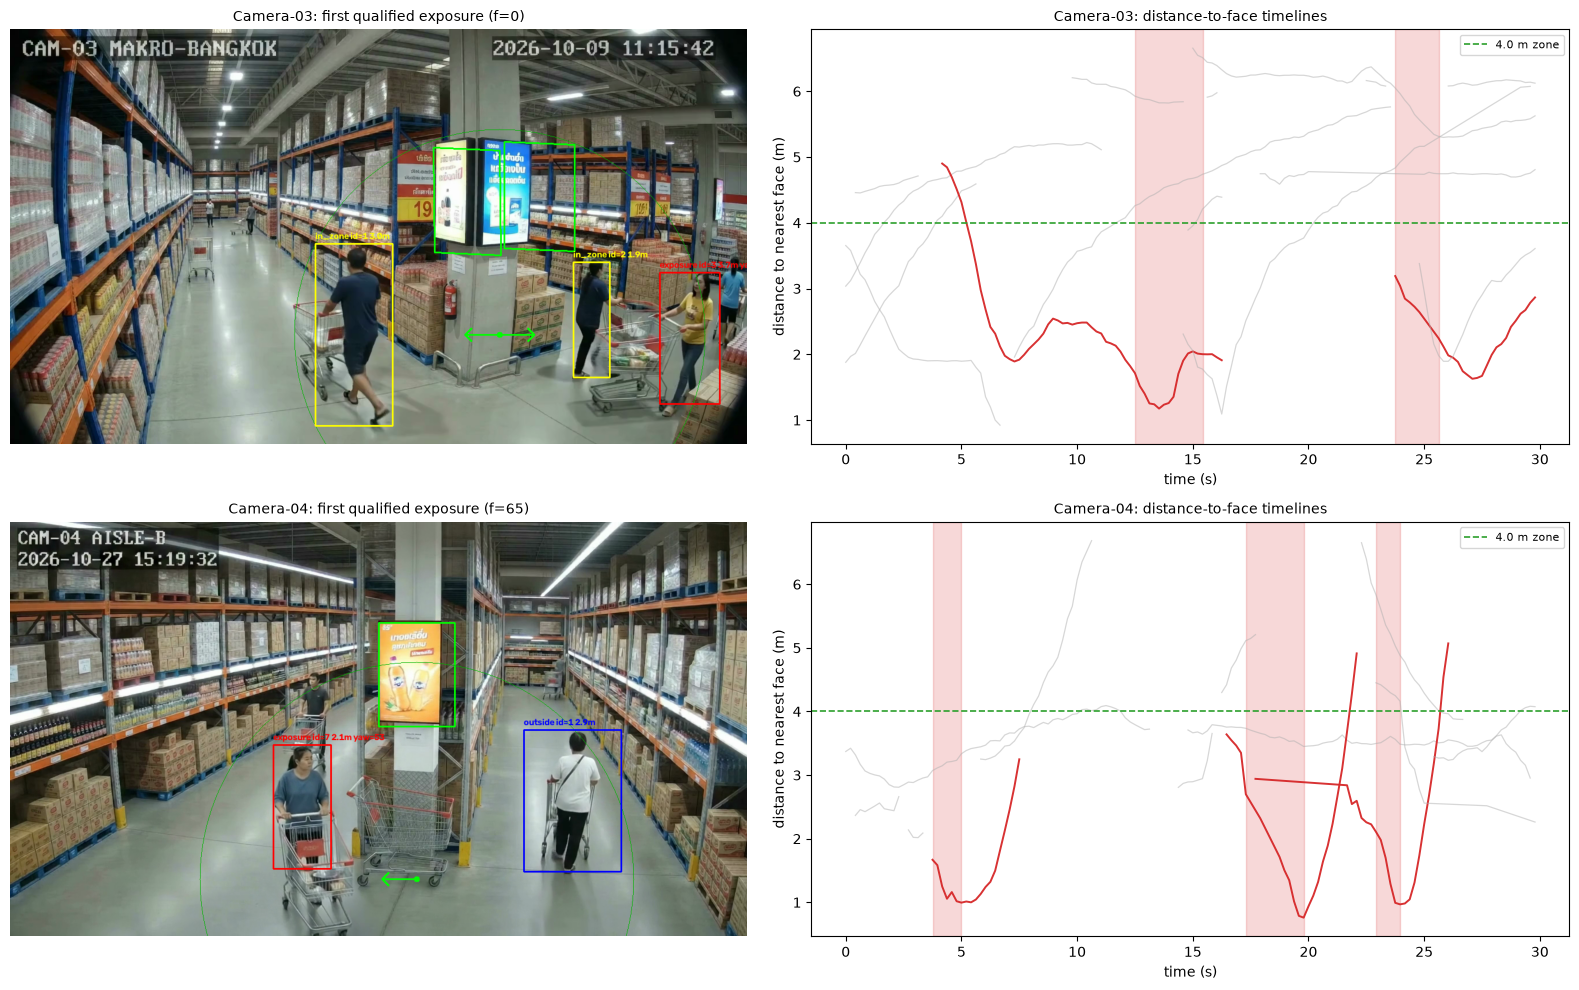

In [7]:
STATE_COLORS_BGR = {"exposure": (0, 0, 255), "in_zone": (0, 255, 255), "outside": (255, 0, 0)}


def det_state(det: dict) -> str:
    if det["qualified"]:
        return "exposure"
    return "in_zone" if det["in_zone"] else "outside"


def draw_overlay(frame, frame_dets, calib: dict):
    for face in calib["faces"]:
        cv2.polylines(frame, [np.array(face["screen_polygon"], np.int32)],
                      True, (0, 255, 0), 2)
        foot_x, foot_y = (int(v) for v in face["screen_foot_px"])
        cv2.circle(frame, (foot_x, foot_y), 5, (0, 255, 0), -1)
        normal = math.radians(float(face.get("screen_normal_deg", 0)))
        tip = (int(foot_x + 60 * math.sin(normal)),
               int(foot_y - 60 * math.cos(normal)))
        cv2.arrowedLine(frame, (foot_x, foot_y), tip, (0, 255, 0), 2, tipLength=0.25)
        ppm = float(face["pixels_per_meter"])
        scale = 0.6 + 0.4 * (foot_y / frame.shape[0])
        radius = int(config["zone_radius_m"] * ppm * scale)
        cv2.circle(frame, (foot_x, foot_y), radius, (0, 180, 0), 1)
    for det in frame_dets:
        state = det_state(det)
        color = STATE_COLORS_BGR[state]
        cv2.rectangle(frame, (det["x1"], det["y1"]), (det["x2"], det["y2"]), color, 2)
        yaw = "" if det["head_yaw_deg"] is None else f" yaw={det['head_yaw_deg']:.0f}"
        cv2.putText(frame, f"{state} id={det['local_id']} {det['min_dist_m']:.1f}m{yaw}",
                    (det["x1"], max(det["y1"] - 8, 18)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
    return frame


def first_qualified_frame(video_rel: str):
    for (video, frame_idx), frame_dets in sorted(frames.items()):
        if video == video_rel and any(det["qualified"] for det in frame_dets):
            return frame_idx
    return None


fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for row_index, entry in enumerate(config["videos"]):
    video_rel = entry["file"]
    calib = calibs[video_rel]
    frame_idx = first_qualified_frame(video_rel)
    if frame_idx is None:
        frame_idx = int(clip_meta[video_rel]["frame_count"] // 2)
        title = f"{entry['screen_name']}: no qualified exposure frame"
    else:
        title = f"{entry['screen_name']}: first qualified exposure (f={frame_idx})"
    frame = read_frame_at(video_rel, frame_idx)
    if frame is not None:
        frame = draw_overlay(frame, frames.get((video_rel, frame_idx), []), calib)
        axes[row_index, 0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    axes[row_index, 0].set_title(title, fontsize=10)
    axes[row_index, 0].axis("off")

    ax = axes[row_index, 1]
    sub = det_frame[det_frame["video"] == video_rel]
    for track_id, track in sub.groupby("local_id"):
        track = track.sort_values("t")
        has_event = ((event_frame["video"] == video_rel)
                     & (event_frame["track"] == track_id)).any()
        ax.plot(track["t"], track["min_dist_m"],
                color="#d62728" if has_event else "#b0b0b0",
                linewidth=1.4 if has_event else 0.9,
                alpha=0.95 if has_event else 0.5)
    ax.axhline(config["zone_radius_m"], color="#2ca02c", linestyle="--",
               linewidth=1.2, label=f"{config['zone_radius_m']} m zone")
    for event in event_frame[event_frame["video"] == video_rel].itertuples():
        ax.axvspan(event.start_s, event.end_s, color="#d62728", alpha=0.18)
    ax.set_title(f"{entry['screen_name']}: distance-to-face timelines", fontsize=10)
    ax.set_xlabel("time (s)")
    ax.set_ylabel("distance to nearest face (m)")
    ax.legend(loc="best", fontsize=8)

plt.tight_layout()
plt.show()


## 7 -- Persist the run

Writes the 30 s SEI table, event audit, track metrics, detections, and frozen run metadata under `artifacts/pipeline/`.


In [8]:
out_dir = ROOT / config["out_dir"]
out_dir.mkdir(parents=True, exist_ok=True)

sei_table.to_csv(out_dir / "sei_table_30s.csv", index=False)
event_frame.to_csv(out_dir / "exposure_events.csv", index=False)
track_frame.to_csv(out_dir / "track_metrics.csv", index=False)
det_export = det_frame.drop(columns=["face_states", "in_zone_faces"], errors="ignore")
det_export.to_csv(out_dir / "detections.csv", index=False)

try:
    git_sha = subprocess.run(["git", "rev-parse", "HEAD"], cwd=ROOT,
                             capture_output=True, text=True, check=True).stdout.strip()
except Exception:
    git_sha = None

run_meta = {
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "git_sha": git_sha,
    "window_s": shared_window_s,
    "config": config,
    "calibrations": calibs,
    "clips": clip_meta,
    "rules": {
        "zone_radius_m": config["zone_radius_m"],
        "facing_tolerance_deg": config["facing_tolerance_deg"],
        "min_exposure_s": config["min_exposure_s"],
        "qualified_view_mode": config["qualified_view_mode"],
        "max_gap_s": config["max_gap_s"],
        "sample_fps": config["sample_fps"],
        "require_front_half": config["require_front_half"],
        "qualified_rule": "pose yaw only",
    },
}
(out_dir / "run_meta.json").write_text(json.dumps(run_meta, indent=2))
print(f"wrote artifacts to {out_dir}")
for name in ["sei_table_30s.csv", "exposure_events.csv", "track_metrics.csv",
             "detections.csv", "run_meta.json"]:
    print(f"  {name}")


wrote artifacts to /Users/dannykhant/Code/cmkl/assignments/POC_RMI_G2/artifacts/pipeline
  sei_table_30s.csv
  exposure_events.csv
  track_metrics.csv
  detections.csv
  run_meta.json


## Freeze / promote

1. Tune `conf`, `imgsz`, `keypoint_conf`, `min_head_px`, `facing_tolerance_deg`, `min_exposure_s`, and calibration polygons in the config/JSON files, then re-run.
2. The 30 s table is the deliverable for this toy dataset. Do not scale it to hourly: two 30 s clips cannot support an hourly SEI or pricing claim.
3. Camera-03's two faces are one combined screen. If the business wants per-face pricing, split them into two screen rows and re-run the event merge as separate screens.
4. Production promotion needs shared 5-minute windows, frozen config, ground-truth scoring (`clip_scores` / `v_clip_validation`), and enough exposure events for confidence intervals to separate screens. This notebook is the runner, not the production scorer.
